Exoplanets projecet

Use the Nasa Exoplanet database to get some insights about exoplanets and their discovery.


In [2]:
# Importing the pandas library for data manipulation and analysis
import pandas as pd

# Importing Plotly Express for high-level, easy-to-use interactive visualizations
import plotly.express as px

# Importing Plotly Graph Objects for more fine-grained control over visualizations
import plotly.graph_objects as go

# Importing NumPy for numerical operations and array manipulation
import numpy as np

# Importing Seaborn for statistical data visualization (optional but can complement Plotly)
import seaborn as sns

import matplotlib.pyplot as plt

from plotly.subplots import make_subplots

import pyvo

%pip install --upgrade kaleido
import kaleido 

from scipy import stats

service = pyvo.dal.TAPService(
    "https://exoplanetarchive.ipac.caltech.edu/TAP"
)


query = """
    SELECT
    pl_name,
    hostname,

    discoverymethod,
    disc_year,
    disc_locale,
    disc_facility,
    disc_telescope,
    disc_instrument,

    pl_rade,
    pl_bmasse,
    pl_orbper,
    pl_orbsmax,
    pl_orbeccen,
    pl_eqt,
    pl_insol,

    st_teff,
    st_mass,
    st_rad,
    st_spectype,
    sy_dist,
    sy_snum,
    sy_pnum

    FROM pscomppars
    join 
"""

result = service.search(query)
df = result.to_table().to_pandas()


print(df.info())

  Attempting uninstall: kaleido
    Found existing installation: kaleido 1.5.0
    Uninstalling kaleido-1.5.0:
      Successfully uninstalled kaleido-1.5.0
Note: you may need to restart the kernel to use updated packages.
<class 'pandas.DataFrame'>
RangeIndex: 6470 entries, 0 to 6469
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pl_name          6470 non-null   str    
 1   hostname         6470 non-null   str    
 2   discoverymethod  6470 non-null   str    
 3   disc_year        6470 non-null   int32  
 4   disc_locale      6470 non-null   str    
 5   disc_facility    6470 non-null   str    
 6   disc_telescope   6470 non-null   str    
 7   disc_instrument  6470 non-null   str    
 8   pl_rade          6420 non-null   float64
 9   pl_bmasse        6439 non-null   float64
 10  pl_orbper        6114 non-null   float64
 11  pl_orbsmax       5972 non-null   float64
 12  pl_orbeccen      5400 non-null   

History: We thought that our system was the only one with planets...

history: How many exoplanets have been discovered per year?

size of planets vs year of discovery

Methods: 

Which discovery method finds the most planets?

Are there statistically significant differences in planet sizes between discovery methods?


The Planets:

avg planets per star

Are larger planets generally more massive? (composition)

Is there a correlation between orbital period and planet temperature?

Are exoplanet masses normally distributed?


Bonus: crossmatch with star type - which star types have the most planets
(star type has influence on formation of planets?)



In [49]:
kaleido.get_chrome_sync()
df.isna().sum()
(df[["pl_rade", "pl_bmasse", "pl_orbper"]]
 .isna().mean() * 100).round(2)

pl_rade      0.77
pl_bmasse    0.48
pl_orbper    5.50
dtype: float64

In [50]:
df_years=df["disc_year"].value_counts()
df_years
# Create a histogram using Plotly Express for the "total_bill" column from the "tips" DataFrame
fig = px.bar(df_years, x=df_years.index, y = df_years.values,
    labels={
        "x": "Discovery Year",
        "y": "Number of Exoplanets (log)"
        },
        log_y=True
        )

# Customize the layout by reducing the gap between adjacent bars in the histogram
fig.update_layout(
    bargap=0.15,
    width=900,
    height=450,
    xaxis=dict(
        tickmode="linear",
        dtick=2,
        tickangle=-45
    ),
    yaxis_title="Number of Exoplanets (log scale)"
)


# Display the histogram
fig.show()
fig.write_image("../figures/discoveries_per_year.pdf")


In [ ]:
df_group=df.groupby(["diec_year"])["sex"]

Why 2014 and 2026 had so many discoveries?
2014: Kepler Mission data
2016: New statistical validation technique (VESPA software)

In [51]:
df_radius = df.dropna(subset=["disc_year", "pl_rade"])
df_radius = df_radius[df_radius["pl_rade"] > 0]
df_radius.head

df_mass = df.dropna(subset=["disc_year", "pl_bmasse"])
df_bmasse = df_radius[df_radius["pl_bmasse"] > 0]
df_bmasse.head

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Planet Radius vs. Discovery Year",
        "Planet Mass vs. Discovery Year"
    ),
    horizontal_spacing=0.12
)

fig.add_trace(
    go.Scatter(
        x=df_radius["disc_year"],
        y=df_radius["pl_rade"],
        mode="markers",
        marker=dict(opacity=0.5),
        name="Planet radius",
        text=df_radius["pl_name"],
        hovertemplate="Planet: %{text}<br>Year: %{x}<br>Radius: %{y:.2f} Earth radii<extra></extra>"
    ),
    row=1, col=1
)

# Second plot: Mass
fig.add_trace(
    go.Scatter(
        x=df_mass["disc_year"],
        y=df_mass["pl_bmasse"],
        mode="markers",
        marker=dict(opacity=0.5),
        name="Planet mass",
        text=df_mass["pl_name"],
        hovertemplate="Planet: %{text}<br>Year: %{x}<br>Mass: %{y:.2f} Earth masses<extra></extra>"
    ),
    row=1, col=2
)
fig.update_xaxes(title_text="Discovery Year", row=1, col=1)
fig.update_xaxes(title_text="Discovery Year", row=1, col=2)
fig.update_yaxes(title_text="Radius (Earth radii)", type="log", row=1, col=1)
fig.update_yaxes(title_text="Mass (Earth masses)", type="log", row=1, col=2)

fig.update_layout(
    title="Exoplanet Size and Mass vs. Discovery Year",
    height=550,
    width=1100,
    showlegend=False
)

#fig = px.scatter(df_radius, x="disc_year", y="pl_rade")

# Displaying the scatter plot
fig.show()

1992 and 1994 "pulsar planets"
dominance of larger planets later on: most used radial velocity method can detect up to certain size
Large Radiuses in 2014 and 2025
V2376 Ori b	2025		Young companion, uncertain physical radius
HD 100546 b	2014		Controversial, possible circumplanetary material



In [52]:
# method vs year of discovery:
df_method = df.dropna(subset=["disc_year", "discoverymethod"])
df_methods = df["discoverymethod"].value_counts()
percentages = df_methods / df_methods.sum() * 100

# Add percentages to legend labels
labels = [
    f"{method} ({percentage:.1f}%)"
    for method, percentage in percentages.items()
]

fig = px.pie(
    values=df_methods.values,
    names=labels,
   
)

fig.update_layout(
    width=650,
    height=450,
    legend=dict(
        x=1.0,
        y=0.5,
        xanchor="left",
        yanchor="middle",
        font=dict(size=11)
    ),
    margin=dict(l=20, r=100, t=50, b=20)
)

fig.update_traces(
    textinfo="none",
    hole=0.25
)




#fig = px.pie(values=df_methods,names=df_methods.index, title=("Disovery Methods"))
#fig.update_traces(
#    textposition='outside',
#    textinfo='label+percent',
#    pull=[0, 0, 0, 0, 0, 0, 0, 0] # Opcional: afasta fatias se quiser
#)

fig.show()
fig.write_image("../figures/discoveries_per_method.pdf")


Most planets were discovered by Transit (measuring difference in luminosity of a star when planet passes in front of star). Followed by radial velocity ( measuring shifts in a star's light caused by the gravitational pull of an orbiting planet), and Microlensing (planet's its gravity acts as a natural lens that bends and magnifies the light of a more distant background star as it passes in front of it)


In [53]:
# Mass and Radius distributions by discovery method

# Filter the discovery methods that had found more than 100 exoplanets.
topmethods = df_methods[df_methods > 100].index
df_topmethods = df[df["discoverymethod"].isin(topmethods)].copy()

from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=2,
    cols=1,
    vertical_spacing=0.12,
    subplot_titles=(
        "Planet Radius by Discovery Method",
        "Planet Mass by Discovery Method"
    )
)

# First plot: Radius
fig.add_trace(
    go.Box(
        x=df_topmethods["discoverymethod"],
        y=df_topmethods["pl_rade"],
        name="Radius (Earth radii)",
        boxpoints="outliers"
    ),
    row=1,
    col=1
)

# Second plot: Mass
fig.add_trace(
    go.Box(
        x=df_topmethods["discoverymethod"],
        y=df_topmethods["pl_bmasse"],
        name="Mass (Earth masses)",
        boxpoints="outliers"
    ),
    row=2,
    col=1
)

fig.update_yaxes(type="log", title_text="Radius (Earth radii)", row=1, col=1)
fig.update_yaxes(type="log", title_text="Mass (Earth masses)", row=2, col=1)

fig.update_layout(
    height=650,
    width=850,
    showlegend=False,
    margin=dict(l=70, r=30, t=65, b=70)
)

fig.write_image("../figures/radius_and_mass_by_method.pdf")
fig.show()



print( "Statistics by radius")
print(
    df_topmethods.groupby("discoverymethod")["pl_rade"]
    .agg(["count", "median", "mean", "std"])
    .sort_values("median")
)
print( "Statistics by Mass")
print(
    df_topmethods.groupby("discoverymethod")["pl_bmasse"]
    .agg(["count", "median", "mean", "std"])
    .sort_values("median")
)

Statistics by radius
                 count  median       mean       std
discoverymethod                                    
Transit           4798    2.46   4.393693  4.561235
Microlensing       294   12.55  10.079524  4.412425
Radial Velocity   1168   12.60   9.784032  4.773934
Statistics by Mass
                 count    median         mean          std
discoverymethod                                           
Transit           4775    6.9900   126.966678   546.540591
Microlensing       294  200.0000   831.911632  1566.553634
Radial Velocity   1204  348.7975  1019.946040  1589.953576


For the most efficient methods (the ones used to find more than 100 planets), we can see that:
- Why has transit such small median (radius and mass)? Larger planets should be easier to identify when they come in front of the star. 
    -> Space telescopes, transit surveys can also detect smaller planets by transit.

Actually, transit is more efficient for finding planets with larger radius, radial velocity and microlensing are more efficient for finding
more massive planets. Larger radius does not always imply  larger mass?




In [54]:
df_mr = df.dropna(
    subset=["pl_rade", "pl_bmasse", "discoverymethod"]
).copy()

df_mr = df_mr[
    (df_mr["pl_rade"] > 0) &
    (df_mr["pl_bmasse"] > 0)
]

fig = px.scatter(
    df_mr.dropna(subset=["pl_rade", "pl_bmasse"]),
    x="pl_rade",
    y="pl_bmasse",
    color="discoverymethod",
    log_x=True,
    log_y=True,
    hover_name="pl_name",
    opacity=0.6,
    labels={
        "pl_rade": "Planet Radius (Earth radii)",
        "pl_bmasse": "Planet Mass (Earth masses)",
        "discoverymethod": "Discovery Method"
    },
   
)
fig.update_layout(
    width=850,
    height=550,
    legend_title="Discovery Method"
)

fig.write_image("../figures/mass_vs_radius.pdf")
fig.show()

rho, p_value = stats.spearmanr(
    df_mr["pl_rade"],
    df_mr["pl_bmasse"]
)

print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.3e}")

Spearman correlation: 0.930
P-value: 0.000e+00


In [55]:

df_non_transit_imaging = df_mr[
    ~df_mr["discoverymethod"].isin( ["Transit","Imaging"])
].copy()
fig = px.scatter(
    df_non_transit_imaging.dropna(subset=["pl_rade", "pl_bmasse"]),
    x="pl_rade",
    y="pl_bmasse",
    color="discoverymethod",
    log_x=True,
    log_y=True,
    hover_name="pl_name",
    opacity=0.6,
    labels={
        "pl_rade": "Planet Radius (Earth radii)",
        "pl_bmasse": "Planet Mass (Earth masses)",
        "discoverymethod": "Discovery Method"
    },
   
)
fig.update_layout(
    width=850,
    height=550,
    legend_title="Discovery Method"
)

fig.write_image("../figures/mass_vs_radius_filtered.pdf")
fig.show()


In [56]:

df_both = df_topmethods.dropna(
    subset=["pl_rade", "pl_bmasse"]
)


for method, group in df_both.groupby("discoverymethod"):

    rho, p = stats.spearmanr(
        group["pl_rade"],
        group["pl_bmasse"]
    )

    print(f"{method}: rho={rho:.3f}, p={p:.3e}")
microlensing = df_both[
    df_both["discoverymethod"] == "Microlensing"
]


Microlensing: rho=0.601, p=2.857e-30
Radial Velocity: rho=0.508, p=1.181e-77
Transit: rho=0.931, p=0.000e+00


For all top methods, we observed a positive correlation between planetary mass and radius was observed for all three discovery methods. 
The strongest correlation occurred among transit-discovered planets (Spearman ρ = 0.931), 
followed by microlensing (ρ = 0.607) and radial velocity (ρ = 0.507). 
All correlations were statistically significant. 
The differences in correlation strength between the methods can be from  differences in the detected planet populations, sample sizes and measurement uncertainties.

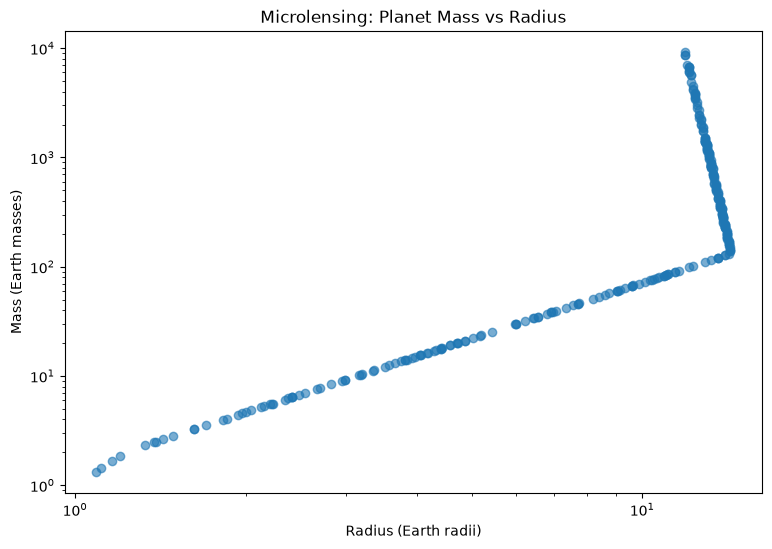

first branch: rho=1.000, p=4.981e-291
second branch: rho=-0.999, p=1.295e-211


In [57]:
plt.figure(figsize=(9, 6))

plt.scatter(
    microlensing["pl_rade"],
    microlensing["pl_bmasse"],
    alpha=0.6
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Radius (Earth radii)")
plt.ylabel("Mass (Earth masses)")
plt.title("Microlensing: Planet Mass vs Radius")

plt.show()

first_branch = microlensing[microlensing["pl_bmasse"]<=135].copy()
second_branch = microlensing[microlensing["pl_bmasse"]>135].copy()
rho, p = stats.spearmanr(
    first_branch["pl_rade"],
    first_branch["pl_bmasse"]
)
print(f"first branch: rho={rho:.3f}, p={p:.3e}")
rho, p = stats.spearmanr(
    second_branch["pl_rade"],
    second_branch["pl_bmasse"]
)
print(f"second branch: rho={rho:.3f}, p={p:.3e}")

The microlensing sample shows a curious behavior. Mass and radius have positive correlation, for igher masses it has a negative correlation. 
Probably this has to do with the gravitational compression in massive gas giant planets, although we have to consider measurement uncertainties and sample size.

In [58]:

print(planets_per_star.describe())


NameError: name 'planets_per_star' is not defined

In [6]:
query = """
    SELECT
    c.pl_name,
    c.hostname,

    c.discoverymethod,
    c.disc_year,
    c.disc_locale,
    c.disc_facility,

    p.pl_rade,
    p.pl_bmasse,

    c.st_teff,
    c.st_mass,
    c.st_rad,
    c.st_spectype,
    c.sy_dist,
    c.sy_snum,
    c.sy_pnum

    FROM pscomppars c, ps p
    WHERE c.pl_name = p.pl_name
    AND p.default_flag=1
"""
from pyvo.dal.exceptions import DALQueryError
try:
    results = service.search(query)
    df_joined = results.to_table().to_pandas()

except DALQueryError as e:
    print("Error:", e)
    print("Query URL:", e.url)
    print("Error label:", e.label)


In [17]:
df_joined.info()
df_ps_mr = df_joined.dropna(
    subset=["pl_rade", "pl_bmasse"]
).copy()

df_ps_mr.info()

fig = px.scatter(
    df_ps_mr,
    x="pl_rade",
    y="pl_bmasse",
    color="discoverymethod",
    log_x=True,
    log_y=True,
    opacity=0.6,
    title="Planet Mass vs. Radius (PS table)"
)

fig.update_layout(
    width=850,
    height=550,
    legend_title="Discovery Method"
)
fig.write_image("../figures/mass_radius_ps.pdf")
fig.show()

<class 'pandas.DataFrame'>
RangeIndex: 6470 entries, 0 to 6469
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pl_name          6470 non-null   str    
 1   hostname         6470 non-null   str    
 2   discoverymethod  6470 non-null   str    
 3   disc_year        6470 non-null   int32  
 4   disc_locale      6470 non-null   str    
 5   disc_facility    6470 non-null   str    
 6   pl_rade          4839 non-null   float64
 7   pl_bmasse        3207 non-null   float64
 8   st_teff          6161 non-null   float64
 9   st_mass          6461 non-null   float64
 10  st_rad           6136 non-null   float64
 11  st_spectype      6470 non-null   str    
 12  sy_dist          6442 non-null   float64
 13  sy_snum          6470 non-null   int32  
 14  sy_pnum          6470 non-null   int32  
dtypes: float64(6), int32(3), str(6)
memory usage: 1012.0 KB
<class 'pandas.DataFrame'>
Index: 1593 entries, 17 to 6467
Da

Average planet/star is 1,33, with the maximum being 8 planets

In [ ]:
# Is there a correlation between orbital period and planet temperature?

corr_data=df.dropna(subset=["pl_orbper", "st_teff"])

fig = px.scatter(
    corr_data,
    x="pl_orbper",
    y="st_teff",
    color="discoverymethod",
    log_x=True,
    log_y=True,
    hover_name="pl_name",
    title="Exoplanet Morbital period vs. star temperature"
)

fig.show()

rho, p = stats.spearmanr(
    corr_data["pl_orbper"],
    corr_data["st_teff"]
)
print(f"orbital period x temperature (spearman): rho={rho:.3f}, p={p:.3e}")
rho, p = stats.pearsonr(
    corr_data["pl_orbper"],
    corr_data["st_teff"]
)
print(f"orbital period x temperature (pearson): rho={rho:.3f}, p={p:.3e}")

orbital period x temperature (spearman): rho=0.044, p=5.636e-04
orbital period x temperature (pearson): rho=-0.015, p=2.410e-01


THe coefficients show that there is no correlation between temperature and orbital period


In [60]:
# planet radius and orbital period:
corr_data=df.dropna(subset=["pl_bmasse", "pl_orbper"])

fig = px.scatter(
    corr_data,
    y="pl_bmasse",
    x="pl_orbper",
    color="discoverymethod",
    log_x=True,
    log_y=True,
    hover_name="pl_name",
    title="Exoplanet  Radius vs Orbital period"
)

fig.show()

rho, p = stats.spearmanr(
    corr_data["pl_bmasse"],
    corr_data["pl_orbper"]
)
print(f"mass orbital period (spearman): rho={rho:.3f}, p={p:.3e}")
rho, p = stats.pearsonr(
    corr_data["pl_bmasse"],
    corr_data["pl_orbper"]
)
print(f"mass vs orbital period  (pearson): rho={rho:.3f}, p={p:.3e}")

mass orbital period (spearman): rho=0.341, p=2.034e-165
mass vs orbital period  (pearson): rho=0.029, p=2.604e-02


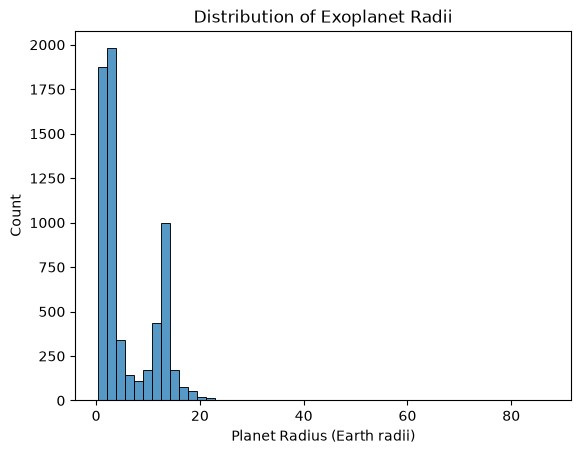

In [ ]:
sns.histplot(
    df["pl_rade"].dropna(),
    bins=50
)
plt.xlabel("Planet Radius (Earth radii)")
plt.title("Distribution of Exoplanet Radii")
plt.show()

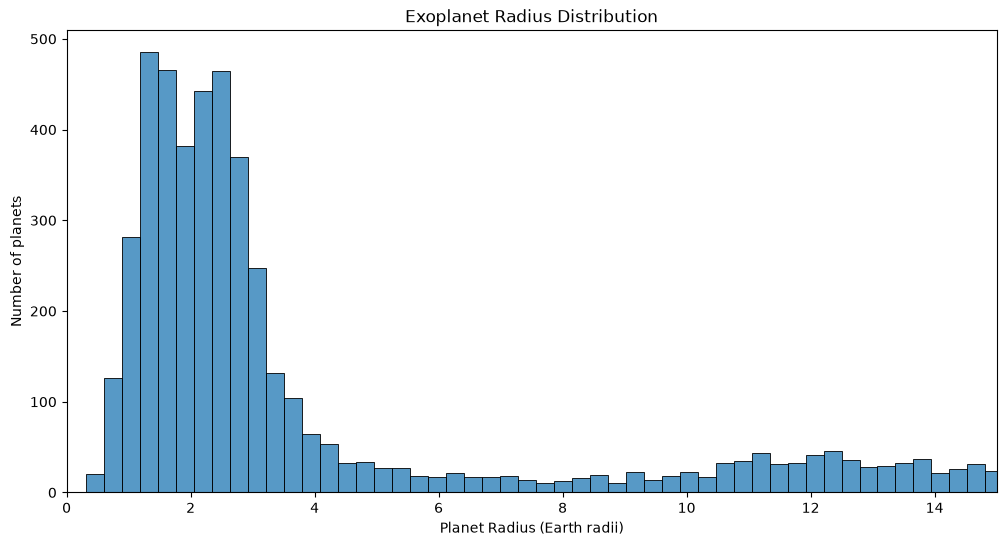

In [ ]:
transit = df[df["discoverymethod"] == "Transit"]

plt.figure(figsize=(12, 6))

sns.histplot(
    transit["pl_rade"].dropna(),
    bins=100
)

plt.xlim(0, 15)
plt.xlabel("Planet Radius (Earth radii)")
plt.ylabel("Number of planets")
plt.title("Exoplanet Radius Distribution")
plt.show()

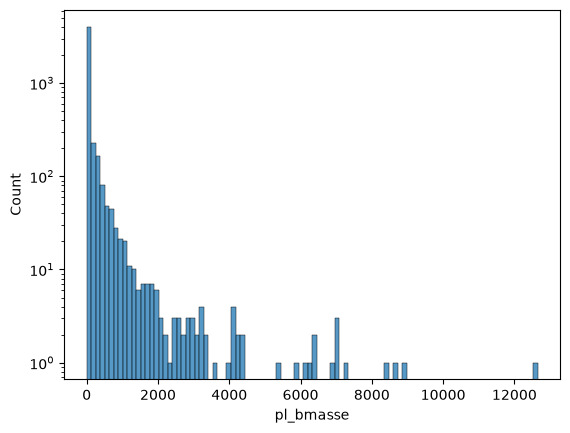

In [ ]:
# Mass distribution
fig = sns.histplot(
    transit["pl_bmasse"].dropna(),
    bins=100
)
fig.set_yscale("log")

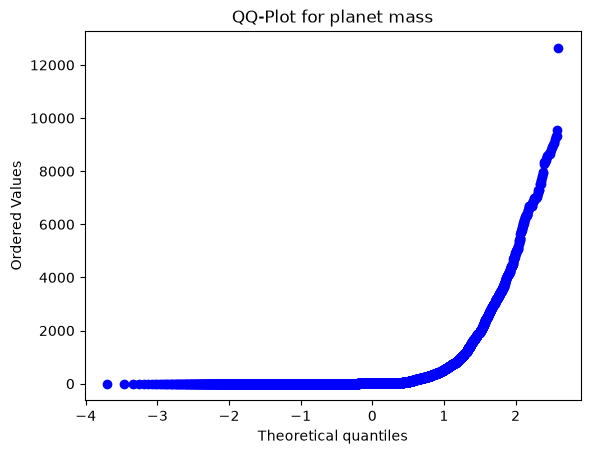

In [ ]:
stats.probplot(df["pl_bmasse"], dist="norm", plot=plt)
plt.title("QQ-Plot for planet mass")
plt.show()

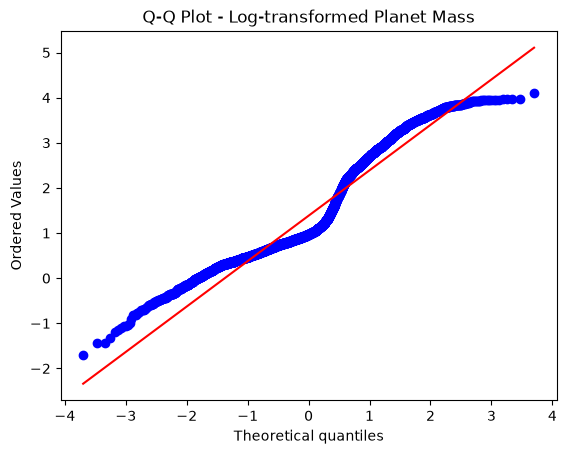

In [ ]:
mass_log = np.log10(df["pl_bmasse"].dropna())

stats.probplot(mass_log, dist="norm", plot=plt)

plt.title("Q-Q Plot - Log-transformed Planet Mass")
plt.show()

In [ ]:
The original planetary mass distribution showed a strong deviation from normality, with pronounced right skewness. 
After applying a logarithmic transformation, the Q-Q plot showed substantially better alignment with the theoretical 
normal distribution. This suggests that planetary masses are approximately log-normally distributed in the analysed 
sample. Physically, this reflects a population spanning several orders of magnitude, with many lower-mass planets and 
progressively fewer very massive planets. However, observational selection effects may also contribute to this distribution.